# 01 – Dataset exploration
**Practicals 1–3:** ML libraries, features / labels / instances, and exploratory data analysis (EDA) for the Annapurna mess food-waste dataset.

In [1]:
import sys, warnings
from pathlib import Path

sys.path.append(str(Path.cwd().parent))   # lets us import from the src/ folder
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
import sklearn
from src.preprocessing import load_raw, REG_FEATURES, REG_TARGET, CLF_TARGET

## Practical 1 – ML libraries

NumPy        : 2.5.5
Pandas       : 3.1.1
Scikit-learn : 1.9.1

NumPy  -> mean: 25.0 | std: 11.18
Pandas -> {'count': 3.0, 'mean': 418.33, 'std': 28.43, 'min': 395.0, '25%': 402.5, '50%': 410.0, '75%': 430.0, 'max': 450.0}


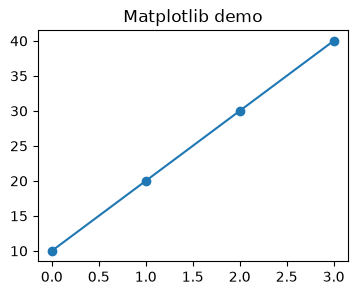

In [2]:
print("NumPy        :", np.__version__)
print("Pandas       :", pd.__version__)
print("Scikit-learn :", sklearn.__version__)

arr = np.array([10, 20, 30, 40])
print("\nNumPy  -> mean:", arr.mean(), "| std:", round(arr.std(), 2))
print("Pandas ->", pd.Series([450, 395, 410]).describe().round(2).to_dict())

plt.figure(figsize=(4, 3))
plt.plot(arr, marker="o")
plt.title("Matplotlib demo")
plt.savefig(FIG_DIR / "p1_matplotlib_demo.png", dpi=100)
plt.show()

## Practical 2 – Features, labels and instances

In [3]:
df = load_raw()
print("Instances (rows):", df.shape[0])
print("Columns         :", df.shape[1])

print("\nFeatures used by the regression model:", REG_FEATURES)
print("Regression label    :", REG_TARGET)
print("Classification label:", CLF_TARGET)

num_cols = df[REG_FEATURES].select_dtypes(include="number").columns.tolist()
cat_cols = df[REG_FEATURES].select_dtypes(exclude="number").columns.tolist()
print("\nNumerical features  :", num_cols)
print("Categorical features:", cat_cols)
df.head()

Instances (rows): 180
Columns         : 14

Features used by the regression model: ['day_of_week', 'meal', 'menu_main', 'exam_week', 'holiday_or_event', 'rain', 'temperature_c', 'students_registered']
Regression label    : plates_eaten
Classification label: high_waste

Numerical features  : ['exam_week', 'holiday_or_event', 'rain', 'temperature_c', 'students_registered']
Categorical features: ['day_of_week', 'meal', 'menu_main']


,date,day_of_week,meal,menu_main,exam_week,holiday_or_event,rain,temperature_c,students_registered,plates_cooked,plates_eaten,leftover_kg,data_source,high_waste
0,2026-09-01,Tuesday,Breakfast,Poha,0,0,1,32.76,194,189,170.0,3.47,simulated,0
1,2026-09-01,Tuesday,Lunch,Chole,0,0,0,32.11,235,227,193.0,4.70,simulated,1
2,2026-09-01,Tuesday,Dinner,Pav Bhaji,0,0,1,28.80,191,177,175.0,0.38,simulated,0
3,2026-09-02,Wednesday,Breakfast,Poha,0,0,0,30.46,218,207,190.0,3.36,simulated,0
4,2026-09-02,Wednesday,Lunch,Dal Rice,0,0,0,33.52,212,198,166.0,5.55,simulated,1


## Practical 3 – Exploratory data analysis

In [4]:
df.info()
print()
print(df.describe().round(2))
print("\nMissing values per column:\n", df.isnull().sum())
print("\nHigh-waste class balance:\n", df["high_waste"].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   date                 180 non-null    str    
 1   day_of_week          180 non-null    str    
 2   meal                 180 non-null    str    
 3   menu_main            180 non-null    str    
 4   exam_week            180 non-null    int64  
 5   holiday_or_event     180 non-null    int64  
 6   rain                 180 non-null    int64  
 7   temperature_c        176 non-null    float64
 8   students_registered  180 non-null    int64  
 9   plates_cooked        180 non-null    int64  
 10  plates_eaten         176 non-null    float64
 11  leftover_kg          180 non-null    float64
 12  data_source          180 non-null    str    
 13  high_waste           180 non-null    int64  
dtypes: float64(3), int64(6), str(5)
memory usage: 26.9 KB

       exam_week  holiday_or_event    rain  te

In [5]:
print("Average leftover (kg) by meal:\n", df.groupby("meal")["leftover_kg"].mean().round(2))
print("\nAverage leftover (kg) by day:\n", df.groupby("day_of_week")["leftover_kg"].mean().round(2))

Average leftover (kg) by meal:
 meal
Breakfast    3.64
Dinner       3.02
Lunch        3.61
Name: leftover_kg, dtype: float64

Average leftover (kg) by day:
 day_of_week
Friday       3.51
Monday       3.29
Saturday     4.01
Sunday       2.38
Thursday     3.37
Tuesday      3.87
Wednesday    3.46
Name: leftover_kg, dtype: float64


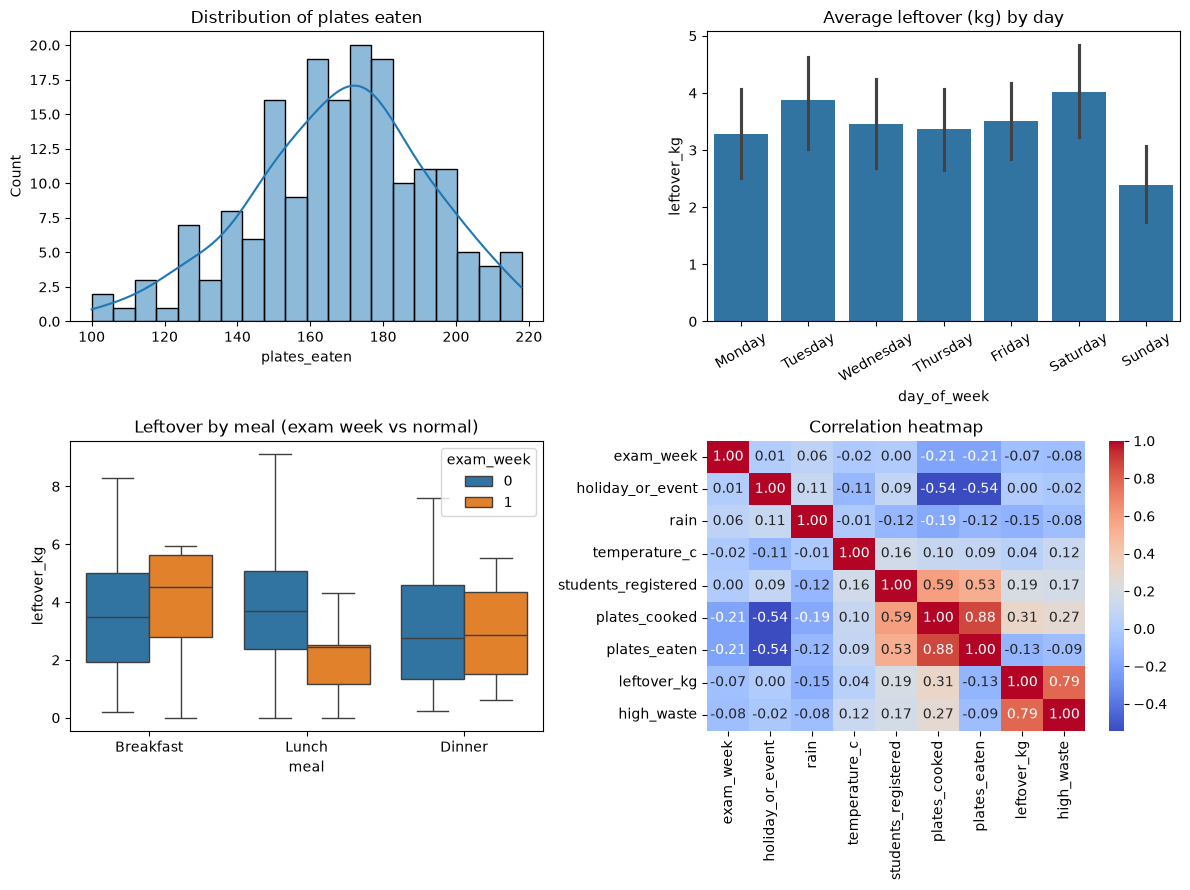

In [6]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
sns.histplot(df["plates_eaten"].dropna(), bins=20, kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Distribution of plates eaten")

sns.barplot(data=df, x="day_of_week", y="leftover_kg", order=order, ax=axes[0, 1])
axes[0, 1].set_title("Average leftover (kg) by day")
axes[0, 1].tick_params(axis="x", rotation=30)

sns.boxplot(data=df, x="meal", y="leftover_kg", hue="exam_week", ax=axes[1, 0])
axes[1, 0].set_title("Leftover by meal (exam week vs normal)")

sns.heatmap(df.select_dtypes(include="number").corr(), annot=True, fmt=".2f",
            cmap="coolwarm", ax=axes[1, 1])
axes[1, 1].set_title("Correlation heatmap")

plt.tight_layout()
plt.savefig(FIG_DIR / "eda_overview.png", dpi=120)
plt.show()

### My observations
*(Write 3–4 lines here in your own words: which day or meal has the most waste, what exam week does, which features correlate with plates eaten.)*